**Name:** Rahul Raj &nbsp;|&nbsp; **Roll No.:** 12341680

# Lab Assignment 10: Multi-Head Attention, Transformer Encoders & Fine-Tuning BERT

**Objective:**
In Lab 8 you built a single attention mechanism inside an LSTM. In Lab 9 you fine-tuned a pre-trained Transformer for translation. In this lab you will **open the black box**: build *scaled dot-product attention* and *multi-head attention* from scratch, assemble them into a mini Transformer encoder, and then compare it with a pre-trained **BERT** model fine-tuned on the same task.

**Task:** Sentiment classification on the **SST-2** dataset (positive / negative movie-review sentences).

**Learning outcomes**
1. Implement scaled dot-product and multi-head attention and verify them against PyTorch.
2. Build a Transformer encoder block (attention + feed-forward + residual + LayerNorm + positional encoding).
3. Understand why BERT (bidirectional, pre-trained encoder) is different from the decoder/LSTM models in previous labs.
4. Fine-tune BERT and evaluate with Accuracy and F1.
5. Visualise and interpret what individual attention heads learn.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 10 |
| 2 | Scaled Dot-Product Attention | 15 |
| 3 | Multi-Head Attention + Encoder Block | 25 |
| 4 | Mini-Transformer trained from scratch | 15 |
| 5 | Fine-tuning BERT | 20 |
| 6 | Attention Head Visualisation | 10 |
| 7 | Comparative Analysis & Reflection | 5 |
| | **Total** | **100** |


## Theory Recap

**Scaled dot-product attention** (Lab 8 used an un-scaled version):

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

* `Q` (queries), `K` (keys), `V` (values) are linear projections of the input.
* Dividing by $\sqrt{d_k}$ stops the dot products from growing large, which would push softmax into regions with tiny gradients.

**Multi-head attention** runs `h` attention operations in parallel, each in a lower-dimensional subspace ($d_k = d_{model}/h$), then concatenates and projects the results:

$$\text{MHA}(X)=\text{Concat}(\text{head}_1,\dots,\text{head}_h)W^O$$

Different heads can specialise (e.g. syntax, neighbouring words, rare-word focus).

**BERT** = a stack of Transformer *encoder* blocks, pre-trained with Masked Language Modelling (MLM) and Next-Sentence Prediction (NSP). The `[CLS]` token's final hidden state is used as the sentence representation for classification.

| Model | Direction | Attention type | Pre-trained? |
|---|---|---|---|
| LSTM + Attention (Lab 8) | Left→right encoder (or BiLSTM) | Cross-attention only | No |
| Marian Transformer (Lab 9) | Encoder-decoder | Self + Cross | Yes |
| **BERT (this lab)** | Encoder only, bidirectional | Self-attention | Yes |


## Part 1: Setup and Data (10 points)

### 1.1 Install & import libraries

In [1]:
# (In Colab use `!pip ...`; `%pip` installs into the *running* kernel's environment, so it works locally too)
%pip install -q transformers datasets evaluate accelerate bertviz scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, math, random, warnings
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"                # PyTorch only - stops transformers from importing TensorFlow/Keras
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

import transformers, datasets
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, DataCollatorWithPadding, pipeline, set_seed)
from datasets import load_dataset
transformers.logging.set_verbosity_error()

# ---- reproducibility ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); set_seed(SEED)

# ---- device: CUDA (Colab T4) > Apple-Silicon MPS > CPU ----
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
USE_FP16 = torch.cuda.is_available()          # fp16 mixed precision is only supported on CUDA GPUs
# PyTorch's fused SDPA kernel does not support attention-dropout on Apple MPS -> use the "eager" attention there
ATTN_IMPL = "eager" if device.type == "mps" else "sdpa"

print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")
print("device:", device, "| fp16:", USE_FP16)

results = {}      # collects Params / Acc / F1 / Train-time for the final comparison table (Part 7)

torch 2.14.1 | transformers 4.57.6 | datasets 5.0.1
device: mps | fp16: False


### 1.2 Load SST-2
Use `load_dataset("glue", "sst2")`. To keep training fast on a Colab T4, use a **subset**: 5,000 training samples and the full validation set (872 samples) as your test set.
Print the dataset structure, 3 random examples, and the class distribution.

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

train = 5000 | val = 872 | test = 872 | labels = ['negative', 'positive']
features: {'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'positive']), 'idx': Value('int32')}

3 random training examples:
  [positive] the road warrior 
  [positive] this movie loves women at all 
  [negative] the story is bogus and its characters tissue-thin 

Class distribution:
              train    val   test
positive    2734.0  491.0  444.0
negative    2266.0  381.0  428.0
% positive    54.7   56.3   50.9


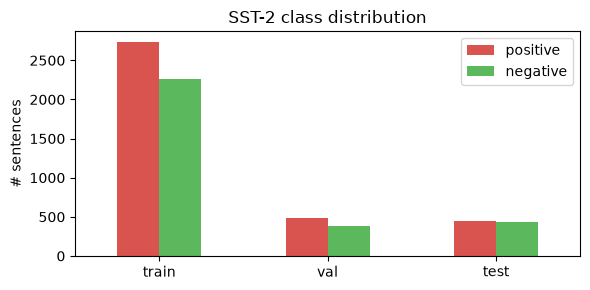

In [3]:
raw = load_dataset("glue", "sst2")
print(raw)

# 5,000 random training sentences. The GLUE *test* split has hidden labels (-1), so - as instructed -
# the labelled GLUE *validation* split (872 sentences) is our TEST set.
# For per-epoch monitoring / model selection we hold out another 872 unused training sentences as a
# separate VALIDATION set, so the test set is never looked at during training.
train_shuffled = raw["train"].shuffle(seed=SEED)
train_ds = train_shuffled.select(range(5000))
val_ds   = train_shuffled.select(range(5000, 5000 + 872))
test_ds  = raw["validation"]
label_names = raw["train"].features["label"].names           # ['negative', 'positive']
print(f"\ntrain = {len(train_ds)} | val = {len(val_ds)} | test = {len(test_ds)} | labels = {label_names}")
print("features:", train_ds.features)

print("\n3 random training examples:")
rng = np.random.default_rng(SEED)
for i in rng.choice(len(train_ds), 3, replace=False):
    ex = train_ds[int(i)]
    print(f"  [{label_names[ex['label']]:8s}] {ex['sentence']}")

dist = pd.DataFrame({name: pd.Series(d["label"]).map(dict(enumerate(label_names))).value_counts()
                     for name, d in [("train", train_ds), ("val", val_ds), ("test", test_ds)]})
dist.loc["% positive"] = (dist.loc["positive"] / dist.sum() * 100).round(1)
print("\nClass distribution:\n", dist)

fig, ax = plt.subplots(figsize=(6, 3))
dist.drop("% positive").T.plot.bar(ax=ax, color=["#d9534f", "#5cb85c"], rot=0)
ax.set_title("SST-2 class distribution"); ax.set_ylabel("# sentences"); plt.tight_layout(); plt.show()

**Observation.** The classes are roughly balanced (~55 % positive in train, ~51 % in test), so accuracy is a meaningful metric. F1 is still reported because it captures the precision/recall trade-off on the positive class. Note that SST-2 *training* items are phrases taken from parse trees, so many are very short ("a masterpiece"); the validation/test items are full sentences.

### 1.3 Tokenize
Load the `bert-base-uncased` tokenizer. Tokenize with `truncation=True`, `max_length=64`, and pad dynamically (use `DataCollatorWithPadding`).
Print one sentence together with its `input_ids`, the decoded tokens (`convert_ids_to_tokens`) and the `attention_mask`. **Explain in a markdown cell:** what are `[CLS]`, `[SEP]` and `##` word-pieces?

In [4]:
MODEL_NAME = "bert-base-uncased"
MAX_LEN = 64
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    # no padding here -> DataCollatorWithPadding pads each mini-batch to its own longest sentence
    return tokenizer(batch["sentence"], truncation=True, max_length=MAX_LEN)

def prepare(ds):
    return (ds.map(tokenize_fn, batched=True, remove_columns=["sentence", "idx"])
              .rename_column("label", "labels"))

train_tok, val_tok, test_tok = prepare(train_ds), prepare(val_ds), prepare(test_ds)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(train_tok)

# pick an example that contains a ## word-piece so all three special cases are visible
ex_idx = next(i for i in range(len(train_ds))
              if any(t.startswith("##") for t in tokenizer.tokenize(train_ds[i]["sentence"]))
              and len(tokenizer.tokenize(train_ds[i]["sentence"])) < 20)
ex = train_tok[ex_idx]
print("\nsentence      :", train_ds[ex_idx]["sentence"])
print("input_ids     :", ex["input_ids"])
print("tokens        :", tokenizer.convert_ids_to_tokens(ex["input_ids"]))
print("attention_mask:", ex["attention_mask"])

# dynamic padding: a batch of 4 is padded only to ITS longest sentence
batch = data_collator([train_tok[i] for i in range(4)])
print("\nDynamic padding - batch input_ids shape:", tuple(batch["input_ids"].shape))
print(batch["attention_mask"])

lens = np.array([len(x) for x in train_tok["input_ids"]] + [len(x) for x in test_tok["input_ids"]])
print(f"\ntoken lengths: mean={lens.mean():.1f}, max={lens.max()}, truncated at {MAX_LEN}: {(lens >= MAX_LEN).mean()*100:.2f}%")

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5000
})

sentence      : be fruitful 
input_ids     : [101, 2022, 5909, 3993, 102]
tokens        : ['[CLS]', 'be', 'fruit', '##ful', '[SEP]']
attention_mask: [1, 1, 1, 1, 1]

Dynamic padding - batch input_ids shape: (4, 17)
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]])

token lengths: mean=15.0, max=59, truncated at 64: 0.00%


**Explanation - special tokens and word-pieces**

* **`[CLS]`** (id 101) is prepended to every input. It is not a real word. Because self-attention lets it attend to every token, its final hidden state is a summary of the whole sequence. BERT is pre-trained (Next-Sentence Prediction) to use this vector, and the classification head in Part 5 sits on top of it.
* **`[SEP]`** (id 102) marks the end of a segment. With sentence pairs (e.g. NLI) it also separates sentence A from sentence B. Here there is only one sentence, so it appears once at the end.
* **`##` word-pieces**: BERT uses a 30,522-entry **WordPiece** vocabulary. Frequent words are single tokens. Rarer words are split into pieces, and every piece after the first is prefixed with `##` to show it continues the previous piece (e.g. `unbelievable` → `un`, `##bel`, `##ie`, `##vable`). This means there are (almost) no out-of-vocabulary words, while the vocabulary stays small.
* **`attention_mask`**: 1 for real tokens and 0 for `[PAD]` tokens added by dynamic padding. Attention uses it to ignore padding, and Part 4 also uses it for mean-pooling.
* **Dynamic padding** (`DataCollatorWithPadding`) pads each batch only to its own longest sentence instead of a fixed 64, which saves compute. The longest sentence here is 59 tokens, so `max_length=64` truncates nothing (0 %).

## Part 2: Scaled Dot-Product Attention from Scratch (15 points)

### 2.1 Implement the function
Write `scaled_dot_product_attention(Q, K, V, mask=None)` that returns `(output, attention_weights)`.

Requirements:
* Input shapes: `(batch, heads, seq_len, d_k)`
* Scale by `sqrt(d_k)`
* If `mask` is given (1 = keep, 0 = padding), set masked scores to a very large negative number **before** softmax
* Do **not** use `nn.MultiheadAttention` or `F.scaled_dot_product_attention` in your implementation

In [5]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q, K, V : (batch, heads, seq_len, d_k)
    mask    : broadcastable to (batch, heads, seq_q, seq_k); 1 = keep, 0 = padding
    returns : output (batch, heads, seq_q, d_k), attention_weights (batch, heads, seq_q, seq_k)
    """
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)            # (B, h, Tq, Tk)
    if mask is not None:
        # very large negative number BEFORE softmax -> exp(.) ~ 0 for padded keys.
        # finfo(dtype).min instead of a hard-coded -1e9 so it also works in fp16 without overflow.
        scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)
    attention_weights = torch.softmax(scores, dim=-1)           # normalise over the KEYS axis
    output = attention_weights @ V                              # weighted average of the values
    return output, attention_weights

### 2.2 Verify
Create random `Q, K, V` and compare your output with `torch.nn.functional.scaled_dot_product_attention` using `torch.allclose`. Also check that every row of the weights sums to 1 and that padded positions receive ~0 weight.

In [6]:
torch.manual_seed(0)
B, h, T, d_k = 2, 4, 6, 16
Q, K, V = (torch.randn(B, h, T, d_k) for _ in range(3))

# padding mask (1 = keep, 0 = pad): sentence 0 has 4 real tokens, sentence 1 has 5
lengths = torch.tensor([4, 5])
pad_mask = (torch.arange(T)[None, :] < lengths[:, None]).long()       # (B, T)
mask = pad_mask[:, None, None, :]                                     # (B, 1, 1, T) -> broadcasts over heads & queries

for name, m in [("no mask", None), ("with padding mask", mask)]:
    out, w = scaled_dot_product_attention(Q, K, V, m)
    ref = F.scaled_dot_product_attention(Q, K, V, attn_mask=None if m is None else m.bool())
    print(f"{name:18s} | output shape {tuple(out.shape)} | allclose with PyTorch: {torch.allclose(out, ref, atol=1e-6)}"
          f" | max |diff| = {(out - ref).abs().max():.2e}")

print("\nweights shape:", tuple(w.shape))
print("every row sums to 1:", torch.allclose(w.sum(-1), torch.ones(B, h, T)))
print("max weight on padded keys :", w.masked_select(mask.expand_as(w) == 0).max().item())
print("\nsentence 0, head 0 weights (last 2 columns = padding):\n", w[0, 0].numpy().round(3))

no mask            | output shape (2, 4, 6, 16) | allclose with PyTorch: True | max |diff| = 2.38e-07
with padding mask  | output shape (2, 4, 6, 16) | allclose with PyTorch: True | max |diff| = 4.77e-07

weights shape: (2, 4, 6, 6)
every row sums to 1: True
max weight on padded keys : 0.0

sentence 0, head 0 weights (last 2 columns = padding):
 [[0.062 0.495 0.372 0.071 0.    0.   ]
 [0.14  0.331 0.408 0.122 0.    0.   ]
 [0.07  0.123 0.625 0.182 0.    0.   ]
 [0.206 0.077 0.132 0.585 0.    0.   ]
 [0.066 0.098 0.78  0.055 0.    0.   ]
 [0.312 0.054 0.018 0.616 0.    0.   ]]


### 2.3 Short question
Compare this with the attention you wrote in **Lab 8** (Bahdanau / dot-product). In 3-4 lines: what is the difference between *additive* and *scaled dot-product* attention, and why does the scaling factor matter? *(Hint: try d_k = 512 with and without scaling and print the std of the scores and the max softmax weight.)*

 d_k  scaled  std(scores)  mean max softmax weight  mean |grad wrt scores|
   4   False         1.68                   0.2478                 0.02327
   4    True       0.8401                   0.1165                 0.02323
  64   False        7.846                   0.8036                0.008305
  64    True       0.9808                   0.1593                 0.02375
 512   False        23.31                   0.9454                0.003274
 512    True         1.03                   0.1673                 0.02441


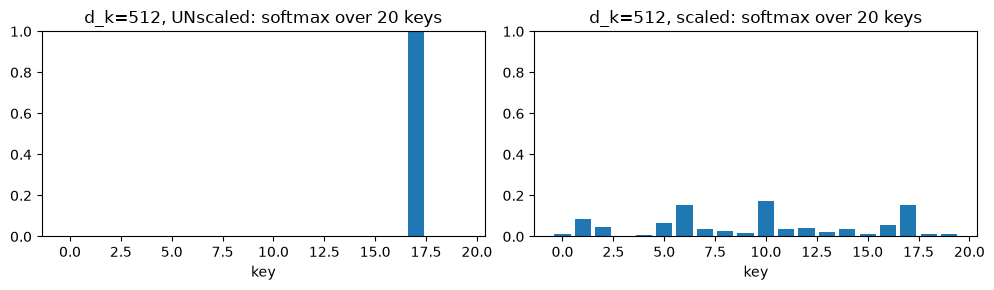

In [7]:
torch.manual_seed(0)
rows = []
for dk in [4, 64, 512]:
    q, k = torch.randn(1, 1, 32, dk), torch.randn(1, 1, 32, dk)
    for scaled in [False, True]:
        scores = (q @ k.transpose(-2, -1)) / (math.sqrt(dk) if scaled else 1.0)
        scores.requires_grad_(True)
        w = torch.softmax(scores, dim=-1)
        (w * torch.randn_like(w)).sum().backward()                # any downstream loss
        rows.append({"d_k": dk, "scaled": scaled,
                     "std(scores)": scores.std().item(),
                     "mean max softmax weight": w.max(-1).values.mean().item(),
                     "mean |grad wrt scores|": scores.grad.abs().mean().item()})
scale_df = pd.DataFrame(rows)
print(scale_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for scaled, ax in zip([False, True], axes):
    q, k = torch.randn(1, 512), torch.randn(20, 512)
    s = (q @ k.T) / (math.sqrt(512) if scaled else 1.0)
    ax.bar(range(20), torch.softmax(s, -1)[0].numpy())
    ax.set_title(f"d_k=512, {'scaled' if scaled else 'UNscaled'}: softmax over 20 keys")
    ax.set_ylim(0, 1); ax.set_xlabel("key")
plt.tight_layout(); plt.show()

**Answer 2.3 - additive vs. scaled dot-product attention**

* **Additive (Bahdanau, Lab 8)** scores each query-key pair with a small feed-forward net: $e = v^\top \tanh(W_1 q + W_2 k)$. It has extra parameters and has to be computed pair by pair. **Scaled dot-product** attention computes $QK^\top/\sqrt{d_k}$. It has no parameters of its own and is a single matrix multiplication, so it is much faster and easier to parallelise on GPUs. Unscaled dot-product (Luong) attention is the same without the $1/\sqrt{d_k}$.
* **Why scaling matters:** if the entries of $q$ and $k$ have unit variance, $q\cdot k$ has variance $d_k$. The table shows the score std growing from 1.7 ($d_k=4$) to **23.3** ($d_k=512$). With such large scores the softmax becomes almost one-hot (mean max weight **0.945** unscaled vs. **0.167** scaled), and its gradients almost vanish (mean |grad| **0.0033** vs. **0.0244**, ≈7.5× smaller), so learning stalls. Dividing by $\sqrt{d_k}$ brings the std back to ≈1 for every $d_k$. That keeps the softmax in a range where it is smooth and trainable.

## Part 3: Multi-Head Attention and the Transformer Encoder Block (25 points)

### 3.1 MultiHeadAttention layer
Implement `class MultiHeadAttention(nn.Module)` with:
* `__init__(self, d_model, num_heads)` — assert `d_model % num_heads == 0`; create `W_q, W_k, W_v, W_o` as `nn.Linear`
* `split_heads(x)` : `(B, T, d_model) -> (B, h, T, d_k)`
* `forward(x, mask=None)` : project → split → attention (your function from Part 2) → merge heads → `W_o`
* store the last attention weights in `self.attn_weights` for visualisation later

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model, self.num_heads = d_model, num_heads
        self.d_k = d_model // num_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.attn_weights = None                       # (B, h, T, T) from the last forward pass

    def split_heads(self, x):
        # (B, T, d_model) -> (B, T, h, d_k) -> (B, h, T, d_k)
        B, T, _ = x.shape
        return x.view(B, T, self.num_heads, self.d_k).transpose(1, 2)

    def merge_heads(self, x):
        # (B, h, T, d_k) -> (B, T, h, d_k) -> (B, T, d_model); reshape because transpose is non-contiguous
        B, h, T, d_k = x.shape
        return x.transpose(1, 2).reshape(B, T, h * d_k)

    def forward(self, x, mask=None):
        Q = self.split_heads(self.W_q(x))
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))
        out, weights = scaled_dot_product_attention(Q, K, V, mask)
        self.attn_weights = weights.detach()
        return self.W_o(self.merge_heads(out))

# quick shape test
_mha = MultiHeadAttention(d_model=128, num_heads=4)
_x = torch.randn(2, 10, 128)
print("in:", tuple(_x.shape), "-> out:", tuple(_mha(_x).shape), "| attn_weights:", tuple(_mha.attn_weights.shape))
print("parameters:", sum(p.numel() for p in _mha.parameters()), "= 4 x (128*128 + 128)")

in: (2, 10, 128) -> out: (2, 10, 128) | attn_weights: (2, 4, 10, 10)
parameters: 66048 = 4 x (128*128 + 128)


### 3.2 Sanity check
Copy the weights of your layer into `nn.MultiheadAttention(d_model, num_heads, batch_first=True)` (hint: its `in_proj_weight` stacks Q, K, V) and confirm the outputs match (`atol=1e-5`).

In [9]:
torch.manual_seed(0)
d_model, n_heads = 64, 8
mine = MultiHeadAttention(d_model, n_heads).eval()
ref  = nn.MultiheadAttention(d_model, n_heads, batch_first=True).eval()

with torch.no_grad():
    # in_proj_weight stacks [W_q; W_k; W_v] -> shape (3*d_model, d_model)
    ref.in_proj_weight.copy_(torch.cat([mine.W_q.weight, mine.W_k.weight, mine.W_v.weight], dim=0))
    ref.in_proj_bias.copy_(torch.cat([mine.W_q.bias, mine.W_k.bias, mine.W_v.bias], dim=0))
    ref.out_proj.weight.copy_(mine.W_o.weight)
    ref.out_proj.bias.copy_(mine.W_o.bias)

    x = torch.randn(3, 7, d_model)
    pad = torch.tensor([[1] * 7, [1] * 5 + [0] * 2, [1] * 3 + [0] * 4])        # 1 = keep, 0 = pad

    for name, m_mine, m_ref in [("no mask", None, None),
                                ("padding mask", pad[:, None, None, :], pad == 0)]:   # PyTorch: True = ignore
        out_mine = mine(x, mask=m_mine)
        out_ref, w_ref = ref(x, x, x, key_padding_mask=m_ref, need_weights=True, average_attn_weights=False)
        print(f"{name:13s} | outputs match: {torch.allclose(out_mine, out_ref, atol=1e-5)} "
              f"(max diff {(out_mine - out_ref).abs().max():.1e}) | "
              f"weights match: {torch.allclose(mine.attn_weights, w_ref, atol=1e-5)}")

no mask       | outputs match: True (max diff 1.2e-07) | weights match: True
padding mask  | outputs match: True (max diff 1.8e-07) | weights match: True


### 3.3 Positional Encoding
Attention has no notion of order. Implement sinusoidal positional encoding and plot it as a heatmap (positions × dimensions).

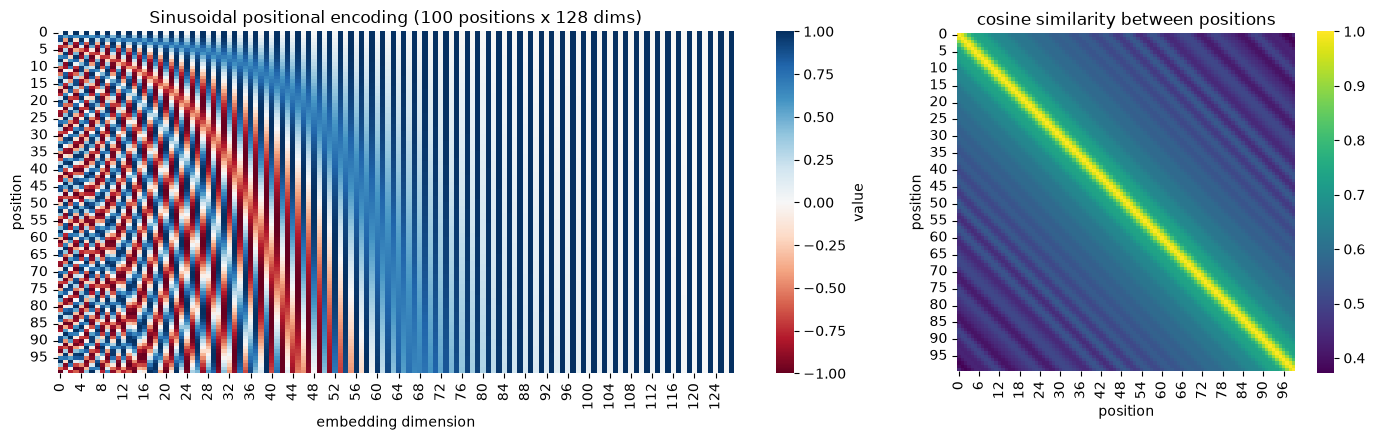

output shape check: (2, 10, 128)


In [10]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float).unsqueeze(1)                    # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))  # 1/10000^(2i/d)
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)       # even dims
        pe[:, 1::2] = torch.cos(position * div_term)       # odd dims
        # buffer = part of the module's state (moves with .to(device), saved in state_dict) but NOT trained
        self.register_buffer("pe", pe.unsqueeze(0))        # (1, max_len, d_model)

    def forward(self, x):
        # x: (B, T, d_model) -> add the encoding of positions 0..T-1
        return x + self.pe[:, : x.size(1)]

pe_layer = PositionalEncoding(d_model=128, max_len=100)
P = pe_layer.pe[0].numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(P, cmap="RdBu", center=0, ax=axes[0], cbar_kws={"label": "value"})
axes[0].set_xlabel("embedding dimension"); axes[0].set_ylabel("position")
axes[0].set_title("Sinusoidal positional encoding (100 positions x 128 dims)")
Pn = P / np.linalg.norm(P, axis=1, keepdims=True)
sns.heatmap(Pn @ Pn.T, cmap="viridis", ax=axes[1], square=True)
axes[1].set_title("cosine similarity between positions"); axes[1].set_xlabel("position"); axes[1].set_ylabel("position")
plt.tight_layout(); plt.show()
print("output shape check:", tuple(pe_layer(torch.zeros(2, 10, 128)).shape))

**Reading the plots.** In the left heatmap, the low dimensions (left) oscillate quickly with position and the high dimensions (right) change very slowly. Each row (position) gets a unique pattern, like the hands of a clock. The right plot shows that the encodings of nearby positions are more similar than those of distant positions, and that this similarity depends only on the *offset*. Because $PE_{pos+k}$ is a linear function of $PE_{pos}$, attention can easily learn relative positions. The encoding is *added* to the token embeddings and has no trainable parameters (`register_buffer`).

### 3.4 Transformer Encoder Block
Implement `EncoderBlock(d_model, num_heads, d_ff, dropout)`:

`x → MHA → Dropout → Add & LayerNorm → FeedForward (Linear-GELU-Linear) → Dropout → Add & LayerNorm`

Then answer in markdown: **Why are residual connections and LayerNorm needed in deep Transformers?**

In [11]:
class EncoderBlock(nn.Module):
    """Post-LN Transformer encoder block (as in the original Transformer and BERT)."""
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.dropout1 = nn.Dropout(dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.dropout2 = nn.Dropout(dropout)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        x = self.norm1(x + self.dropout1(self.mha(x, mask)))      # sub-layer 1: self-attention + Add & Norm
        x = self.norm2(x + self.dropout2(self.ffn(x)))            # sub-layer 2: position-wise FFN + Add & Norm
        return x

_blk = EncoderBlock(d_model=128, num_heads=4, d_ff=256)
_x = torch.randn(2, 10, 128)
_m = torch.ones(2, 1, 1, 10); _m[1, ..., 7:] = 0
print("in:", tuple(_x.shape), "-> out:", tuple(_blk(_x, _m).shape), "(same shape, so blocks can be stacked)")
print("parameters per block:", sum(p.numel() for p in _blk.parameters()))

in: (2, 10, 128) -> out: (2, 10, 128) (same shape, so blocks can be stacked)
parameters per block: 132480


**Why are residual connections and LayerNorm needed in deep Transformers?**

* **Residual (skip) connections** ($x + \text{SubLayer}(x)$) create an identity path, so gradients can reach early layers without being multiplied through every attention/FFN Jacobian. This prevents vanishing or exploding gradients in deep stacks (BERT-base has 12 blocks = 24 sub-layers; the tutorial demo shows a plain 30-layer stack losing the input signal). Each sub-layer also only has to learn a *refinement* (a residual) of its input, which is easier to optimise. The original token information is kept as well, which matters because attention averages across tokens and could otherwise wash it out.
* **LayerNorm** re-centres and re-scales each token vector to zero mean and unit variance (plus learned gain/bias). Without it, repeatedly adding sub-layer outputs makes activation magnitudes drift from layer to layer. That shifts attention logits into saturated softmax regions and makes training sensitive to the learning rate. LayerNorm keeps every layer's inputs on a stable scale, which allows higher learning rates and faster, steadier convergence. It normalises per token, so unlike BatchNorm it does not depend on batch size or padding.

## Part 4: Mini-Transformer Classifier Trained from Scratch (15 points)

### 4.1 Build the model
Create `MiniTransformerClassifier` using: token embedding (use the BERT tokenizer's vocab size) → positional encoding → **2** `EncoderBlock`s (`d_model=128`, `heads=4`, `d_ff=256`) → mean-pool over non-padding tokens → `Linear(d_model, 2)`.
Print the number of trainable parameters.

In [12]:
class MiniTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, d_ff=256, num_layers=2,
                 num_classes=2, max_len=512, dropout=0.1, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_enc = PositionalEncoding(d_model, max_len)
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask):
        x = self.dropout(self.pos_enc(self.embedding(input_ids)))      # (B, T, d_model)
        mask = attention_mask[:, None, None, :]                        # (B, 1, 1, T) -> broadcasts to (B, h, T, T)
        for block in self.blocks:
            x = block(x, mask)
        # mean-pool over NON-padding tokens only
        m = attention_mask.unsqueeze(-1).float()                       # (B, T, 1)
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1.0)              # (B, d_model)
        return self.classifier(pooled)                                 # (B, 2) logits

def count_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

torch.manual_seed(SEED)
mini_model = MiniTransformerClassifier(tokenizer.vocab_size, pad_idx=tokenizer.pad_token_id).to(device)
print(mini_model)
n_emb = mini_model.embedding.weight.numel()
print(f"\ntrainable parameters: {count_params(mini_model):,}")
print(f"  token embedding : {n_emb:,} ({n_emb / count_params(mini_model) * 100:.1f}%)")
print(f"  encoder blocks  : {sum(p.numel() for p in mini_model.blocks.parameters()):,}")
print(f"  classifier      : {sum(p.numel() for p in mini_model.classifier.parameters()):,}")

MiniTransformerClassifier(
  (embedding): Embedding(30522, 128, padding_idx=0)
  (pos_enc): PositionalEncoding()
  (dropout): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-1): 2 x EncoderBlock(
      (mha): MultiHeadAttention(
        (W_q): Linear(in_features=128, out_features=128, bias=True)
        (W_k): Linear(in_features=128, out_features=128, bias=True)
        (W_v): Linear(in_features=128, out_features=128, bias=True)
        (W_o): Linear(in_features=128, out_features=128, bias=True)
      )
      (dropout1): Dropout(p=0.1, inplace=False)
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=128, bias=True)
      )
      (dropout2): Dropout(p=0.1, inplace=False)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    )
  )
  (classi

### 4.2 Train
Write a standard PyTorch training loop (AdamW, lr=1e-3, 5 epochs, batch size 32). Log train loss and validation accuracy per epoch and plot both curves.
Note the padding mask must be built from `attention_mask` and reshaped to `(B, 1, 1, T)`.

epoch 1 | train loss 0.6752 | train acc 0.5932 | val acc 0.6376


epoch 2 | train loss 0.5882 | train acc 0.6850 | val acc 0.6846


epoch 3 | train loss 0.4817 | train acc 0.7638 | val acc 0.7431


epoch 4 | train loss 0.3843 | train acc 0.8312 | val acc 0.7523


epoch 5 | train loss 0.3071 | train acc 0.8788 | val acc 0.7546

total training time: 17.7s | best val acc 0.7546 at epoch 5 (weights restored)


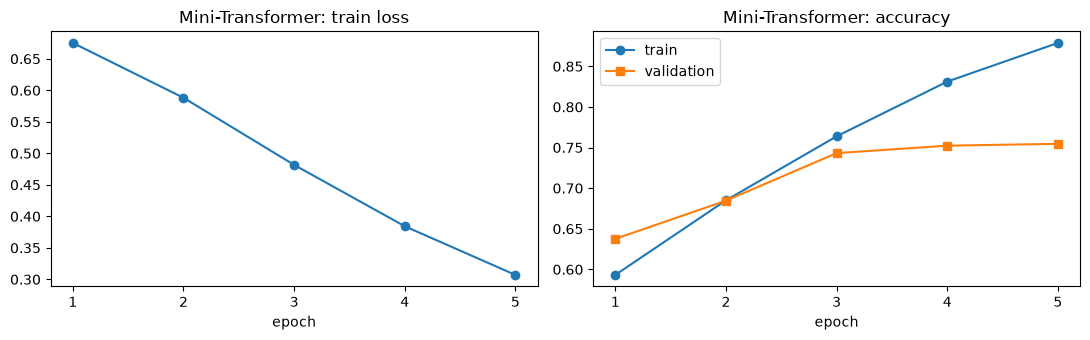

In [13]:
BATCH_SIZE, EPOCHS, LR = 32, 5, 1e-3
train_loader = DataLoader(train_tok, batch_size=BATCH_SIZE, shuffle=True, collate_fn=data_collator,
                          generator=torch.Generator().manual_seed(SEED))
val_loader  = DataLoader(val_tok,  batch_size=64, collate_fn=data_collator)
test_loader = DataLoader(test_tok, batch_size=64, collate_fn=data_collator)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for batch in loader:
        logits = model(batch["input_ids"].to(device), batch["attention_mask"].to(device))
        preds.append(logits.argmax(-1).cpu()); labels.append(batch["labels"])
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

optimizer = torch.optim.AdamW(mini_model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()
history = {"train_loss": [], "train_acc": [], "val_acc": []}
best_val, best_state = -1, None

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    mini_model.train()
    tot_loss, correct, n = 0.0, 0, 0
    for batch in train_loader:
        ids, att, y = batch["input_ids"].to(device), batch["attention_mask"].to(device), batch["labels"].to(device)
        optimizer.zero_grad()
        logits = mini_model(ids, att)
        loss = loss_fn(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(mini_model.parameters(), 1.0)
        optimizer.step()
        tot_loss += loss.item() * len(y); correct += (logits.argmax(-1) == y).sum().item(); n += len(y)
    vp, vl = predict(mini_model, val_loader)
    val_acc = accuracy_score(vl, vp)
    history["train_loss"].append(tot_loss / n); history["train_acc"].append(correct / n); history["val_acc"].append(val_acc)
    if val_acc > best_val:                                   # keep the best epoch (selected on VAL, not test)
        best_val, best_epoch = val_acc, epoch
        best_state = {k: v.detach().clone() for k, v in mini_model.state_dict().items()}
    print(f"epoch {epoch} | train loss {tot_loss / n:.4f} | train acc {correct / n:.4f} | val acc {val_acc:.4f}")
mini_train_time = time.time() - t0
mini_model.load_state_dict(best_state)
print(f"\ntotal training time: {mini_train_time:.1f}s | best val acc {best_val:.4f} at epoch {best_epoch} (weights restored)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ep = range(1, EPOCHS + 1)
axes[0].plot(ep, history["train_loss"], "o-"); axes[0].set_title("Mini-Transformer: train loss")
axes[1].plot(ep, history["train_acc"], "o-", label="train"); axes[1].plot(ep, history["val_acc"], "s-", label="validation")
axes[1].set_title("Mini-Transformer: accuracy"); axes[1].legend()
for ax in axes: ax.set_xlabel("epoch"); ax.set_xticks(list(ep))
plt.tight_layout(); plt.show()

**Observation.** Training loss falls steadily (0.675 → 0.307) and validation accuracy rises from 63.8 % to **75.5 %** at epoch 5. The gap between train accuracy (87.9 %) and validation accuracy grows every epoch, so the model is starting to **overfit**. That is expected: it has 4.2 M parameters, 93.6 % of them in the embedding table, and only 5,000 mostly short phrases, so many words are seen once or never. The weights from the epoch with the best *validation* accuracy are restored before testing (epoch 5 in this run). This simple early stopping never touches the test set.

### 4.3 Evaluate
Report accuracy, F1 and the confusion matrix on the test set. Record the **total training time**.

Mini-Transformer  TEST accuracy = 0.7213 | F1 = 0.7466 | training time = 17.7s

              precision    recall  f1-score   support

    negative     0.7591    0.6332    0.6904       428
    positive     0.6951    0.8063    0.7466       444

    accuracy                         0.7213       872
   macro avg     0.7271    0.7197    0.7185       872
weighted avg     0.7265    0.7213    0.7190       872



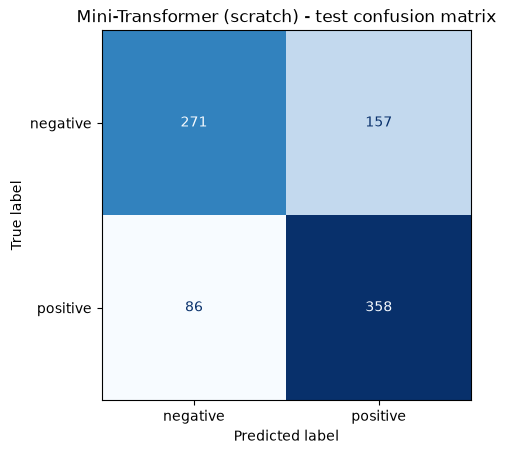

In [14]:
test_pred, test_lab = predict(mini_model, test_loader)
mini_acc, mini_f1 = accuracy_score(test_lab, test_pred), f1_score(test_lab, test_pred)
print(f"Mini-Transformer  TEST accuracy = {mini_acc:.4f} | F1 = {mini_f1:.4f} | training time = {mini_train_time:.1f}s\n")
print(classification_report(test_lab, test_pred, target_names=label_names, digits=4))

ConfusionMatrixDisplay(confusion_matrix(test_lab, test_pred), display_labels=label_names).plot(cmap="Blues", colorbar=False)
plt.title("Mini-Transformer (scratch) - test confusion matrix"); plt.show()

results["Mini-Transformer (scratch)"] = {"Params": count_params(mini_model), "Trainable": count_params(mini_model),
                                         "Pre-trained": "No", "Test Acc": mini_acc, "Test F1": mini_f1,
                                         "Train time (s)": mini_train_time}

**Result.** On the test set the scratch model reaches **72.1 % accuracy / 0.747 F1** after only **17.7 s** of training. That is clearly better than chance (50.9 %) but well below BERT (Part 5). Test accuracy is a little lower than validation accuracy (75.5 %), because the validation phrases come from the same distribution as the short training phrases, while the test items are full, longer sentences. The confusion matrix shows a bias towards *positive*: recall is 0.81 for positive but only 0.63 for negative. Many negative reviews contain positive words ("not bad", "good intentions but…"), and a 2-layer model trained on 5 k examples cannot resolve this composition reliably.

## Part 5: Fine-Tuning BERT (20 points)

### 5.1 Load the pre-trained model
Load `AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)`. Print the parameter count and compare it with your mini-Transformer.

In [15]:
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {v: k for k, v in id2label.items()}

def load_bert(name=MODEL_NAME):
    return AutoModelForSequenceClassification.from_pretrained(name, num_labels=2, id2label=id2label, label2id=label2id,
                                              attn_implementation=ATTN_IMPL)

set_seed(SEED)
bert_model = load_bert()
n_bert, n_mini = count_params(bert_model), count_params(mini_model)
print(f"BERT-base parameters       : {n_bert:,}")
print(f"  embeddings               : {sum(p.numel() for p in bert_model.bert.embeddings.parameters()):,}")
print(f"  12 encoder layers        : {sum(p.numel() for p in bert_model.bert.encoder.parameters()):,}")
print(f"  pooler                   : {sum(p.numel() for p in bert_model.bert.pooler.parameters()):,}")
print(f"  classifier head (new)    : {sum(p.numel() for p in bert_model.classifier.parameters()):,}")
print(f"Mini-Transformer parameters: {n_mini:,}")
print(f"-> BERT is {n_bert / n_mini:.1f}x larger (12 layers x 12 heads x 768 hidden vs 2 x 4 x 128)")

BERT-base parameters       : 109,483,778
  embeddings               : 23,837,184
  12 encoder layers        : 85,054,464
  pooler                   : 590,592
  classifier head (new)    : 1,538
Mini-Transformer parameters: 4,172,034
-> BERT is 26.2x larger (12 layers x 12 heads x 768 hidden vs 2 x 4 x 128)


### 5.2 Metrics
Define `compute_metrics` that returns **accuracy** and **F1** (use `evaluate` or `sklearn`).

In [16]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds)}

# sanity check on fake logits
print(compute_metrics((np.array([[2.0, -1.0], [0.1, 0.3], [1.0, 0.0]]), np.array([0, 1, 1]))))

{'accuracy': 0.6666666666666666, 'f1': 0.6666666666666666}


### 5.3 Configure and run training
Use `TrainingArguments`: `learning_rate=2e-5`, `num_train_epochs=3`, `per_device_train_batch_size=32`, `weight_decay=0.01`, `eval_strategy="epoch"`, `fp16=True` (GPU), `report_to="none"`. Train with `Trainer` and record training time.

In [17]:
OUT_DIR = "outputs"
FT_DIR = os.path.join(OUT_DIR, "bert-sst2-finetuned")

def make_args(run_name, lr):
    return TrainingArguments(
        output_dir=os.path.join(OUT_DIR, run_name),
        learning_rate=lr,
        num_train_epochs=3,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=64,
        weight_decay=0.01,
        eval_strategy="epoch",
        logging_strategy="epoch",
        save_strategy="no",               # keep the disk clean; final model saved explicitly below
        fp16=USE_FP16,                     # True on a CUDA GPU (Colab T4); not supported on MPS/CPU
        report_to="none",
        seed=SEED,
    )

def run_trainer(model, run_name, lr, train=train_tok, val=val_tok, test=test_tok, collator=data_collator, tok=tokenizer):
    trainer = Trainer(model=model, args=make_args(run_name, lr), train_dataset=train, eval_dataset=val,
                      data_collator=collator, compute_metrics=compute_metrics, processing_class=tok)
    t0 = time.time()
    trainer.train()
    train_time = time.time() - t0
    logs = pd.DataFrame([l for l in trainer.state.log_history if "eval_accuracy" in l])[
        ["epoch", "eval_loss", "eval_accuracy", "eval_f1"]]
    train_loss = [l["loss"] for l in trainer.state.log_history if "loss" in l]
    logs.insert(1, "train_loss", train_loss[: len(logs)])
    print(logs.to_string(index=False))
    test_m = trainer.evaluate(test, metric_key_prefix="test")
    print(f"\n{run_name}: TEST accuracy = {test_m['test_accuracy']:.4f} | F1 = {test_m['test_f1']:.4f} "
          f"| training time = {train_time:.1f}s")
    return trainer, test_m, train_time

set_seed(SEED)
bert_trainer, bert_test, bert_time = run_trainer(bert_model, "bert-full", lr=2e-5)
bert_trainer.save_model(FT_DIR); tokenizer.save_pretrained(FT_DIR)

results["BERT (full fine-tune)"] = {"Params": count_params(bert_model, False), "Trainable": count_params(bert_model),
                                    "Pre-trained": "Yes", "Test Acc": bert_test["test_accuracy"],
                                    "Test F1": bert_test["test_f1"], "Train time (s)": bert_time}

{'loss': 0.3781, 'grad_norm': 11.705939292907715, 'learning_rate': 1.337579617834395e-05, 'epoch': 1.0}


{'eval_loss': 0.22631311416625977, 'eval_accuracy': 0.9139908256880734, 'eval_f1': 0.9221183800623053, 'eval_runtime': 3.4319, 'eval_samples_per_second': 254.083, 'eval_steps_per_second': 4.079, 'epoch': 1.0}


{'loss': 0.1898, 'grad_norm': 4.529860973358154, 'learning_rate': 6.709129511677282e-06, 'epoch': 2.0}


{'eval_loss': 0.22706831991672516, 'eval_accuracy': 0.9197247706422018, 'eval_f1': 0.9276859504132231, 'eval_runtime': 5.1672, 'eval_samples_per_second': 168.757, 'eval_steps_per_second': 2.709, 'epoch': 2.0}


{'loss': 0.1102, 'grad_norm': 50.39975357055664, 'learning_rate': 4.246284501061571e-08, 'epoch': 3.0}


{'eval_loss': 0.2821606993675232, 'eval_accuracy': 0.9185779816513762, 'eval_f1': 0.9265770423991727, 'eval_runtime': 5.5233, 'eval_samples_per_second': 157.876, 'eval_steps_per_second': 2.535, 'epoch': 3.0}
{'train_runtime': 329.3592, 'train_samples_per_second': 45.543, 'train_steps_per_second': 1.43, 'train_loss': 0.22602685090083224, 'epoch': 3.0}
 epoch  train_loss  eval_loss  eval_accuracy  eval_f1
   1.0      0.3781   0.226313       0.913991 0.922118
   2.0      0.1898   0.227068       0.919725 0.927686
   3.0      0.1102   0.282161       0.918578 0.926577


{'test_loss': 0.3488684892654419, 'test_accuracy': 0.8956422018348624, 'test_f1': 0.8992248062015504, 'test_runtime': 6.4417, 'test_samples_per_second': 135.369, 'test_steps_per_second': 2.173, 'epoch': 3.0}

bert-full: TEST accuracy = 0.8956 | F1 = 0.8992 | training time = 329.6s


**Why such a small learning rate (2e-5)?** BERT's weights already encode a lot of linguistic knowledge from pre-training. Fine-tuning should only *nudge* them towards sentiment. A large learning rate would overwrite this knowledge (*catastrophic forgetting*) and make training unstable. Only the new 2-way head starts from random weights. BERT reaches its best validation accuracy within 1-3 epochs.

### 5.4 Ablation: frozen vs. full fine-tuning
Re-load a fresh BERT and **freeze all encoder layers** (`for p in model.bert.parameters(): p.requires_grad = False`) so only the classifier head trains. Train with the same settings (you may use lr=1e-3).
Report a table with *trainable parameters*, *accuracy*, *F1*, and *training time* for: frozen BERT vs. fully fine-tuned BERT.

In [18]:
set_seed(SEED)
frozen_model = load_bert()
for p in frozen_model.bert.parameters():          # freeze embeddings + 12 encoder layers + pooler
    p.requires_grad = False
print(f"trainable parameters: {count_params(frozen_model):,} / {count_params(frozen_model, False):,} "
      f"({count_params(frozen_model) / count_params(frozen_model, False) * 100:.4f}%)\n")

frozen_trainer, frozen_test, frozen_time = run_trainer(frozen_model, "bert-frozen", lr=1e-3)

results["BERT (frozen, head only)"] = {"Params": count_params(frozen_model, False), "Trainable": count_params(frozen_model),
                                       "Pre-trained": "Yes", "Test Acc": frozen_test["test_accuracy"],
                                       "Test F1": frozen_test["test_f1"], "Train time (s)": frozen_time}

ablation = pd.DataFrame({k: results[k] for k in ["BERT (frozen, head only)", "BERT (full fine-tune)"]}).T[
    ["Trainable", "Test Acc", "Test F1", "Train time (s)"]].rename(columns={"Trainable": "Trainable params"})
ablation["Trainable params"] = ablation["Trainable params"].map(lambda x: f"{int(x):,}")
for c in ["Test Acc", "Test F1"]: ablation[c] = ablation[c].map(lambda x: f"{x:.4f}")
ablation["Train time (s)"] = ablation["Train time (s)"].map(lambda x: f"{x:.1f}")
ablation

trainable parameters: 1,538 / 109,483,778 (0.0014%)



{'loss': 0.6571, 'grad_norm': 2.277514934539795, 'learning_rate': 0.0006687898089171975, 'epoch': 1.0}


{'eval_loss': 0.6017282605171204, 'eval_accuracy': 0.6605504587155964, 'eval_f1': 0.7573770491803279, 'eval_runtime': 5.9246, 'eval_samples_per_second': 147.183, 'eval_steps_per_second': 2.363, 'epoch': 1.0}


{'loss': 0.6125, 'grad_norm': 3.949230432510376, 'learning_rate': 0.0003354564755838641, 'epoch': 2.0}


{'eval_loss': 0.5771900415420532, 'eval_accuracy': 0.6995412844036697, 'eval_f1': 0.7790893760539629, 'eval_runtime': 7.3423, 'eval_samples_per_second': 118.764, 'eval_steps_per_second': 1.907, 'epoch': 2.0}


{'loss': 0.5988, 'grad_norm': 4.549072265625, 'learning_rate': 2.1231422505307854e-06, 'epoch': 3.0}


{'eval_loss': 0.5676079988479614, 'eval_accuracy': 0.7213302752293578, 'eval_f1': 0.7866549604916594, 'eval_runtime': 6.0717, 'eval_samples_per_second': 143.616, 'eval_steps_per_second': 2.306, 'epoch': 3.0}
{'train_runtime': 129.676, 'train_samples_per_second': 115.673, 'train_steps_per_second': 3.632, 'train_loss': 0.6228063951885118, 'epoch': 3.0}
 epoch  train_loss  eval_loss  eval_accuracy  eval_f1
   1.0      0.6571   0.601728       0.660550 0.757377
   2.0      0.6125   0.577190       0.699541 0.779089
   3.0      0.5988   0.567608       0.721330 0.786655


{'test_loss': 0.5845122337341309, 'test_accuracy': 0.7029816513761468, 'test_f1': 0.7545023696682465, 'test_runtime': 6.9918, 'test_samples_per_second': 124.717, 'test_steps_per_second': 2.002, 'epoch': 3.0}

bert-frozen: TEST accuracy = 0.7030 | F1 = 0.7545 | training time = 130.0s


,Trainable params,Test Acc,Test F1,Train time (s)
"BERT (frozen, head only)","1,538",0.7030,0.7545,130.0
BERT (full fine-tune),"109,483,778",0.8956,0.8992,329.6


**Frozen vs. full fine-tuning.**

| | Trainable params | Test Acc | Test F1 | Train time |
|---|---|---|---|---|
| BERT frozen (head only, lr 1e-3) | 1,538 | 0.7030 | 0.7545 | 130.0 s |
| BERT full fine-tune (lr 2e-5) | 109,483,778 | **0.8956** | **0.8992** | 329.6 s |

* **Full fine-tuning wins by ~19 accuracy points.** The frozen `[CLS]`/pooler vector was pre-trained for Masked LM and Next-Sentence Prediction, not sentiment. A single linear layer on top of it can only find a direction that is roughly sentiment-related. Full fine-tuning adapts all 12 layers, so the `[CLS]` vector itself becomes a sentiment summary.
* **The frozen model is ~2.5× faster** because no gradients are computed or stored for the encoder (forward pass only, and an optimiser over 1.5 k numbers). Its validation accuracy was still rising after 3 epochs (66.1 → 70.0 → 72.1 %), so more epochs would help a little.
* The frozen model's F1 (0.755) is higher than its accuracy because it predicts *positive* too often (high recall, low precision). Its inference scores in 5.5 are all close to 0.5, which shows how weakly separable the frozen features are.

### 5.5 Inference
Use `pipeline("text-classification", model=..., tokenizer=...)` to classify these sentences, and add **3 of your own** (include one sarcastic and one negated sentence):
```python
tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
]
```

In [19]:
tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
    # --- my own sentences ---
    "Oh great, another two-hour 'thriller' where nothing happens. Just what I always wanted.",   # sarcastic
    "I can't say I didn't enjoy it, but it is certainly not a film I would recommend.",          # negation(s)
    "Despite a painfully slow first act, the ending left me in tears of joy.",                   # contrast
]
kinds = ["given"] * 4 + ["own: sarcastic", "own: negated", "own: contrast"]

clf_full   = pipeline("text-classification", model=bert_trainer.model, tokenizer=tokenizer, device=device)
clf_frozen = pipeline("text-classification", model=frozen_trainer.model, tokenizer=tokenizer, device=device)

rows = []
for s, kind, pf, pz in zip(tests, kinds, clf_full(tests), clf_frozen(tests)):
    rows.append({"type": kind, "sentence": s,
                 "full FT": f"{pf['label']} ({pf['score']:.3f})",
                 "frozen": f"{pz['label']} ({pz['score']:.3f})"})
pd.set_option("display.max_colwidth", 100)
pd.DataFrame(rows)

,type,sentence,full FT,frozen
0,given,This movie was an absolute masterpiece.,POSITIVE (0.996),POSITIVE (0.632)
1,given,I wasted two hours of my life on this film.,NEGATIVE (0.988),NEGATIVE (0.614)
2,given,The acting was not bad at all.,POSITIVE (0.976),POSITIVE (0.528)
3,given,"The plot was predictable, but the visuals were stunning.",POSITIVE (0.995),POSITIVE (0.766)
4,own: sarcastic,"Oh great, another two-hour 'thriller' where nothing happens. Just what I always wanted.",POSITIVE (0.988),NEGATIVE (0.504)
5,own: negated,"I can't say I didn't enjoy it, but it is certainly not a film I would recommend.",NEGATIVE (0.989),POSITIVE (0.507)
6,own: contrast,"Despite a painfully slow first act, the ending left me in tears of joy.",POSITIVE (0.993),POSITIVE (0.733)


**Inference analysis.**

* The **fully fine-tuned BERT** gets all four given sentences right with high confidence. That includes the negation *"not bad at all" → POSITIVE (0.976)* and the contrast *"predictable, but … stunning" → POSITIVE*, where the clause after *but* decides the sentiment.
* **My negated sentence** (*"I can't say I didn't enjoy it, but it is certainly not a film I would recommend."*) has a double negation followed by a negated recommendation. It is correctly classified **NEGATIVE (0.989)**.
* **My contrast sentence** (*"Despite a painfully slow first act, the ending left me in tears of joy."*) is correctly **POSITIVE (0.993)**.
* **My sarcastic sentence** (*"Oh great, … where nothing happens. Just what I always wanted."*) is **misclassified as POSITIVE (0.988)**. Sarcasm is a classic failure case: the surface words (*great*, *always wanted*) are positive, and recognising the irony needs pragmatic knowledge that 5,000 SST-2 phrases do not teach. The model is also *very confident* while being wrong, so softmax confidence is not a reliable error signal.
* The **frozen BERT** outputs ~0.5-0.77 for everything and gets both the sarcastic and the negated sentence wrong, which confirms the ablation result.

## Part 6: Visualising Attention Heads (10 points)

### 6.1 Extract attentions
Load your fine-tuned BERT with `output_attentions=True` and run one sentence. `outputs.attentions` is a tuple of 12 tensors with shape `(1, 12, T, T)` — one per layer.

In [20]:
attn_model = AutoModelForSequenceClassification.from_pretrained(
    FT_DIR, output_attentions=True, attn_implementation="eager").to(device).eval()

sentence = "The acting was not bad at all, but the plot was painfully predictable."
inputs = tokenizer(sentence, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = attn_model(**inputs)

attentions = tuple(a.cpu() for a in outputs.attentions)        # 12 x (1, 12, T, T)
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
probs = outputs.logits.softmax(-1)[0].cpu()
print("tokens:", tokens)
print(f"# layers = {len(attentions)} | shape per layer = {tuple(attentions[0].shape)}")
print(f"prediction: {id2label[int(probs.argmax())]} (p = {probs.max():.3f})")

tokens: ['[CLS]', 'the', 'acting', 'was', 'not', 'bad', 'at', 'all', ',', 'but', 'the', 'plot', 'was', 'painfully', 'predictable', '.', '[SEP]']
# layers = 12 | shape per layer = (1, 12, 17, 17)
prediction: NEGATIVE (p = 0.995)


**Quantifying head behaviour.** One sentence is not enough to make reliable claims about a head, so each of the 144 heads is summarised with simple statistics averaged over **200 test sentences**: the average weight a token puts on the **previous** token, the **next** token, **itself**, **`[CLS]`**, and **`[SEP]`**, plus the **normalised entropy** of its attention rows (1 = uniform, 0 = one-hot).

pattern        best head  avg weight
   prev  layer 4, head 6       0.706
   next layer 3, head 10       0.950
   self  layer 3, head 7       0.491
  [CLS]  layer 2, head 7       0.882
  [SEP]  layer 5, head 4       0.856

per-layer average over heads:
             L1     L2     L3     L4     L5     L6     L7     L8     L9    L10    L11    L12
prev     0.124  0.092  0.050  0.105  0.045  0.057  0.107  0.094  0.037  0.051  0.038  0.038
next     0.096  0.074  0.197  0.079  0.074  0.105  0.072  0.086  0.070  0.061  0.055  0.050
self     0.076  0.070  0.100  0.080  0.072  0.068  0.072  0.081  0.076  0.105  0.128  0.113
[CLS]    0.125  0.358  0.338  0.222  0.039  0.028  0.027  0.029  0.036  0.064  0.062  0.052
[SEP]    0.052  0.064  0.079  0.252  0.565  0.549  0.500  0.460  0.506  0.389  0.367  0.346
entropy  0.762  0.614  0.519  0.562  0.443  0.395  0.419  0.440  0.514  0.607  0.556  0.645


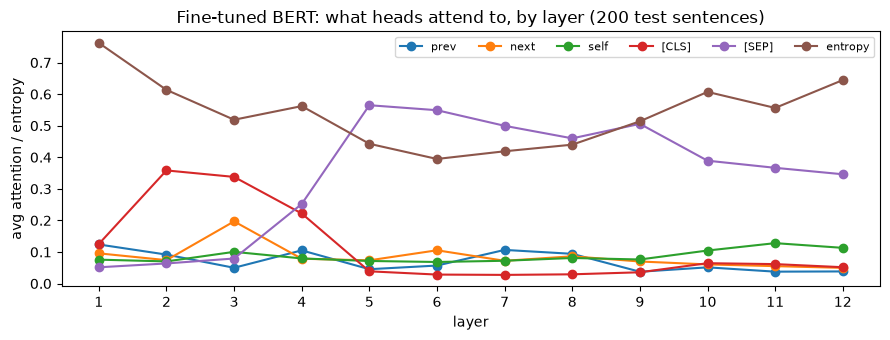

In [21]:
@torch.no_grad()
def head_stats(model, sentences, get_attn):
    """Average per-(layer, head) statistics over many sentences. get_attn(model, enc) -> list of (h, T, T)."""
    acc = None
    for s in sentences:
        enc = tokenizer(s, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
        A = torch.stack(get_attn(model, enc))                     # (L, H, T, T)
        T = A.shape[-1]
        idx = torch.arange(T)
        st = torch.stack([
            A[..., idx[1:], idx[:-1]].mean(-1),                    # previous token
            A[..., idx[:-1], idx[1:]].mean(-1),                    # next token
            A[..., idx, idx].mean(-1),                             # self
            A[..., :, 0].mean(-1),                                 # [CLS]
            A[..., :, T - 1].mean(-1),                             # [SEP]
            (-(A * (A + 1e-12).log()).sum(-1) / math.log(T)).mean(-1),   # normalised entropy
        ], -1)                                                     # (L, H, 6)
        acc = st if acc is None else acc + st
    return (acc / len(sentences)).numpy()

STAT_NAMES = ["prev", "next", "self", "[CLS]", "[SEP]", "entropy"]
probe = [s for s in test_ds["sentence"][:200]]
bert_get = lambda m, enc: [a[0].cpu() for a in m(**enc).attentions]
S = head_stats(attn_model, probe, bert_get)                       # (12, 12, 6)

top = []
for j, name in enumerate(STAT_NAMES[:5]):
    l, h = np.unravel_index(S[..., j].argmax(), S[..., j].shape)
    top.append({"pattern": name, "best head": f"layer {l + 1}, head {h + 1}", "avg weight": round(float(S[l, h, j]), 3)})
print(pd.DataFrame(top).to_string(index=False))

layer_avg = pd.DataFrame(S.mean(1), columns=STAT_NAMES, index=[f"L{i}" for i in range(1, 13)])
print("\nper-layer average over heads:\n", layer_avg.round(3).T.to_string())

fig, ax = plt.subplots(figsize=(9, 3.5))
for c in STAT_NAMES:
    ax.plot(range(1, 13), layer_avg[c], "o-", label=c)
ax.set_xlabel("layer"); ax.set_xticks(range(1, 13)); ax.set_ylabel("avg attention / entropy")
ax.set_title("Fine-tuned BERT: what heads attend to, by layer (200 test sentences)"); ax.legend(ncol=6, fontsize=8)
plt.tight_layout(); plt.show()

### 6.2 Heatmaps
Plot a **grid of 4 heads** (e.g. layer 1 vs layer 12, two heads each) as heatmaps with tokens on the axes. Then use `bertviz` (`head_view` or `model_view`) to produce an interactive view.

> In Colab the `bertviz` call must be the last line of the cell.

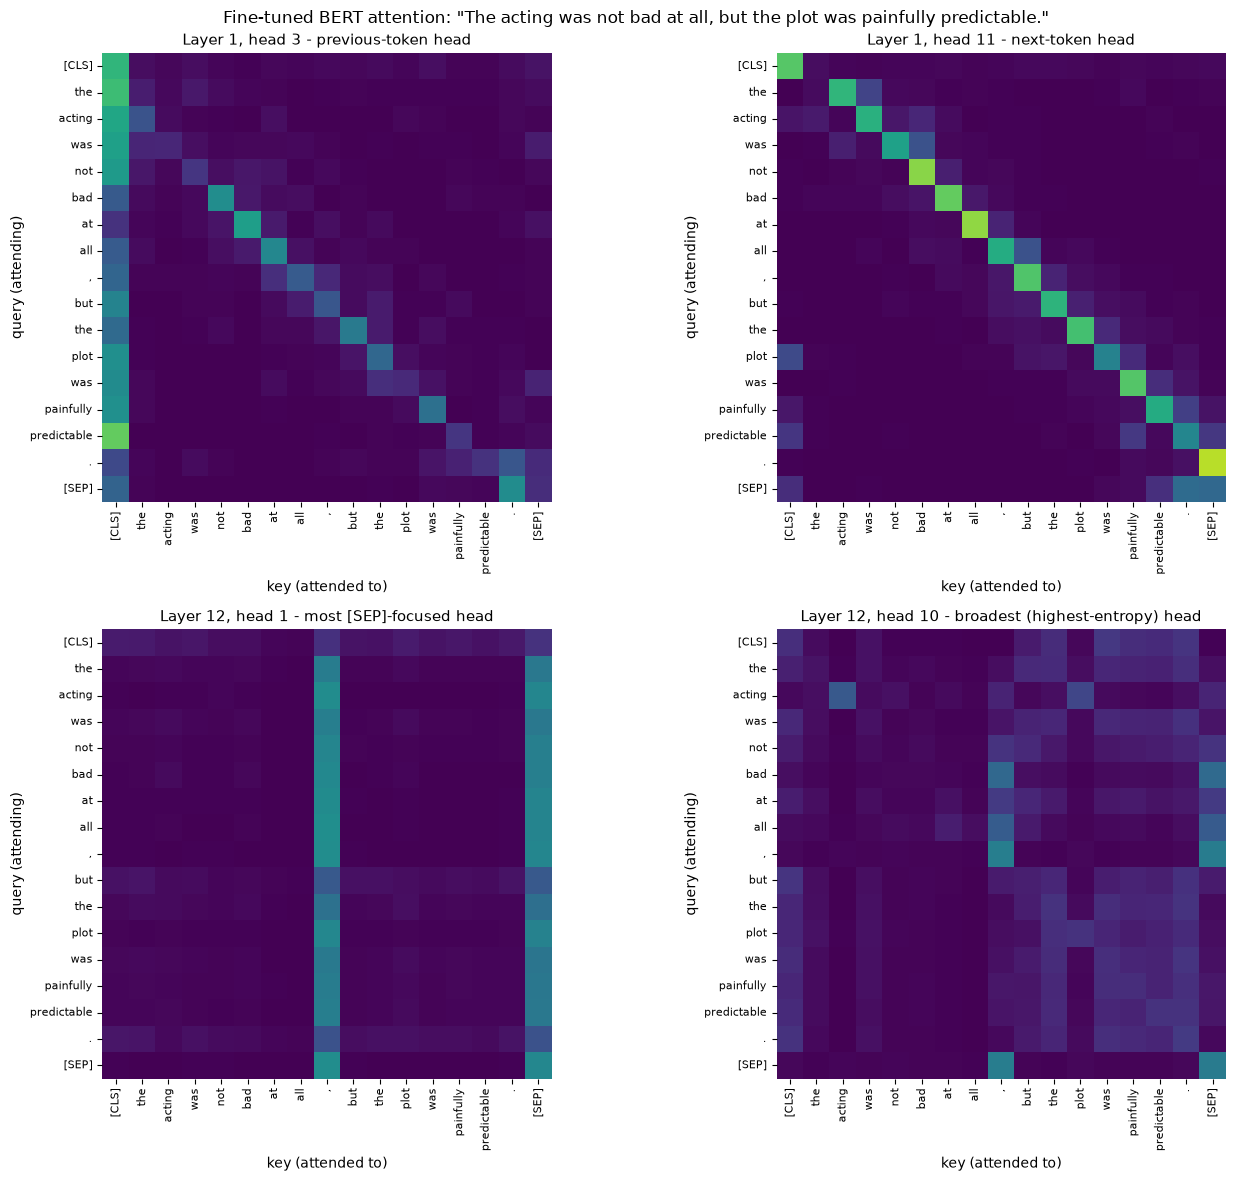

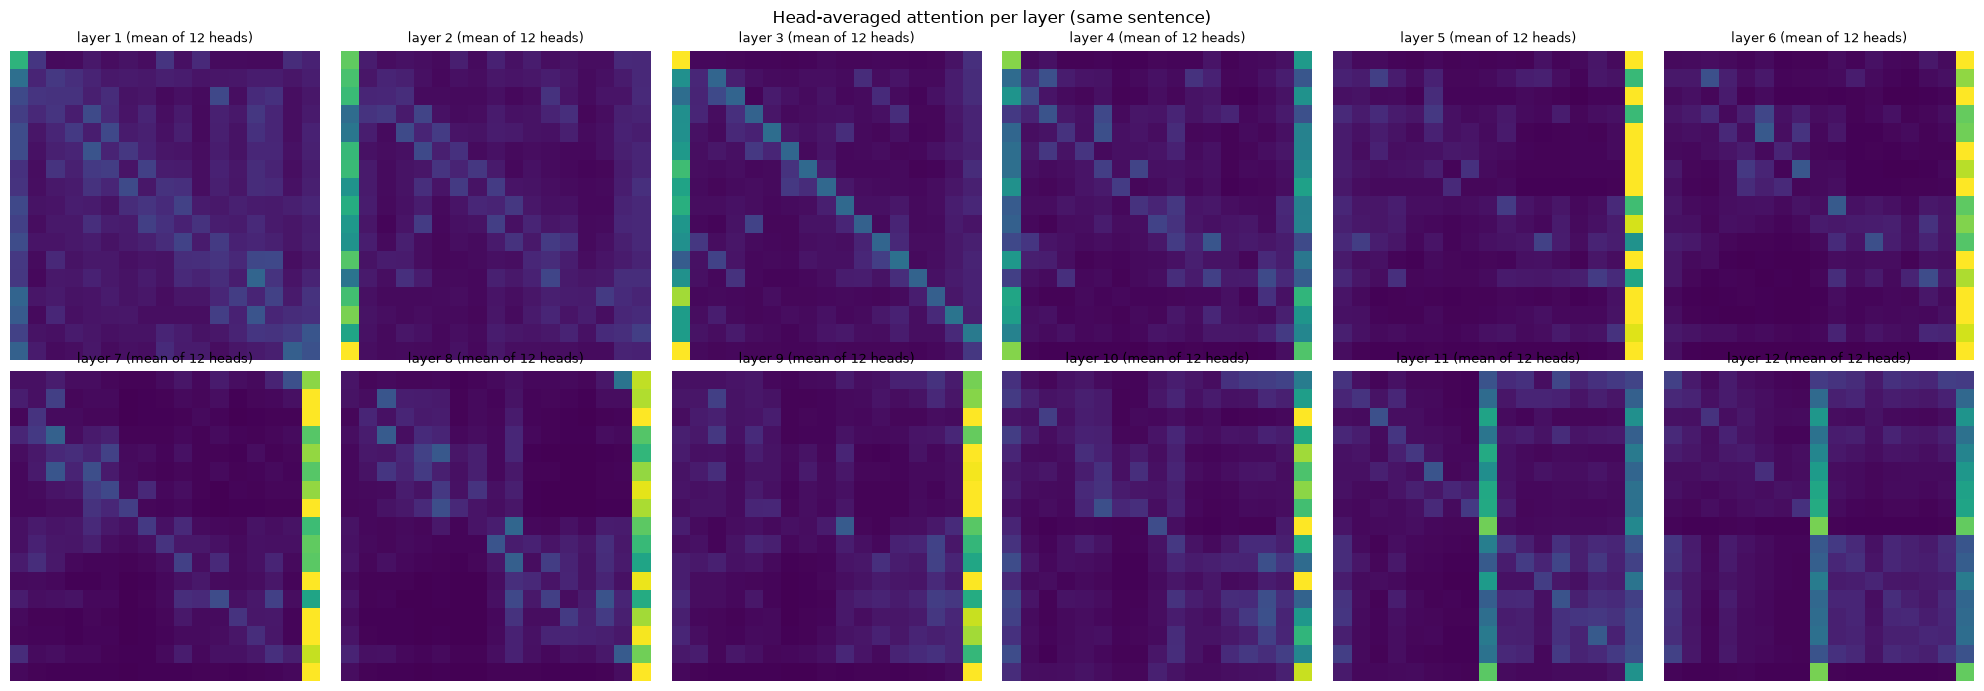

In [22]:
def best_head(layer, stat):
    j = STAT_NAMES.index(stat)
    return int(S[layer, :, j].argmax())

# layer 1 vs layer 12, two heads each - chosen from the statistics above to show distinct patterns
panels = [(0, best_head(0, "prev"), "layer 1: previous-token head"),
          (0, best_head(0, "next"), "layer 1: next-token head"),
          (11, best_head(11, "[SEP]"), "layer 12: most [SEP]-focused head"),
          (11, int(S[11, :, 5].argmax()), "layer 12: broadest (highest-entropy) head")]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (l, h, title) in zip(axes.ravel(), panels):
    sns.heatmap(attentions[l][0, h].numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis",
                ax=ax, square=True, vmin=0, vmax=1, cbar=False)
    ax.set_title(f"Layer {l + 1}, head {h + 1} - {title.split(': ')[1]}", fontsize=11)
    ax.set_xlabel("key (attended to)"); ax.set_ylabel("query (attending)")
    ax.tick_params(axis="x", rotation=90, labelsize=8); ax.tick_params(axis="y", rotation=0, labelsize=8)
plt.suptitle(f'Fine-tuned BERT attention: "{sentence}"', fontsize=12)
plt.tight_layout(); plt.show()

# overview: head-averaged attention for all 12 layers
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for l, ax in enumerate(axes.ravel()):
    sns.heatmap(attentions[l][0].mean(0).numpy(), ax=ax, cmap="viridis", cbar=False, square=True,
                xticklabels=False, yticklabels=False, vmin=0, vmax=0.6)
    ax.set_title(f"layer {l + 1} (mean of 12 heads)", fontsize=9)
plt.suptitle("Head-averaged attention per layer (same sentence)"); plt.tight_layout(); plt.show()

**Interactive view (bertviz).** Pick a layer from the drop-down and hover over a token to see where each of the 12 heads (colours) sends its attention. *(bertviz renders with JavaScript. If the widget is blank in a static viewer, re-run the cell in Jupyter/Colab.)*

In [23]:
from bertviz import head_view
head_view(list(attentions), tokens)

<IPython.core.display.Javascript object>

### 6.3 Interpret
In markdown, answer:
1. Do you find a head that mostly attends to the **next / previous token**? To `[SEP]` or `[CLS]`?
2. How do attention patterns differ between **early** and **late** layers?
3. Compare to your from-scratch model's `attn_weights` (Part 3). Are they as structured? Why / why not?

mini-Transformer prediction: NEGATIVE (p = 0.958)


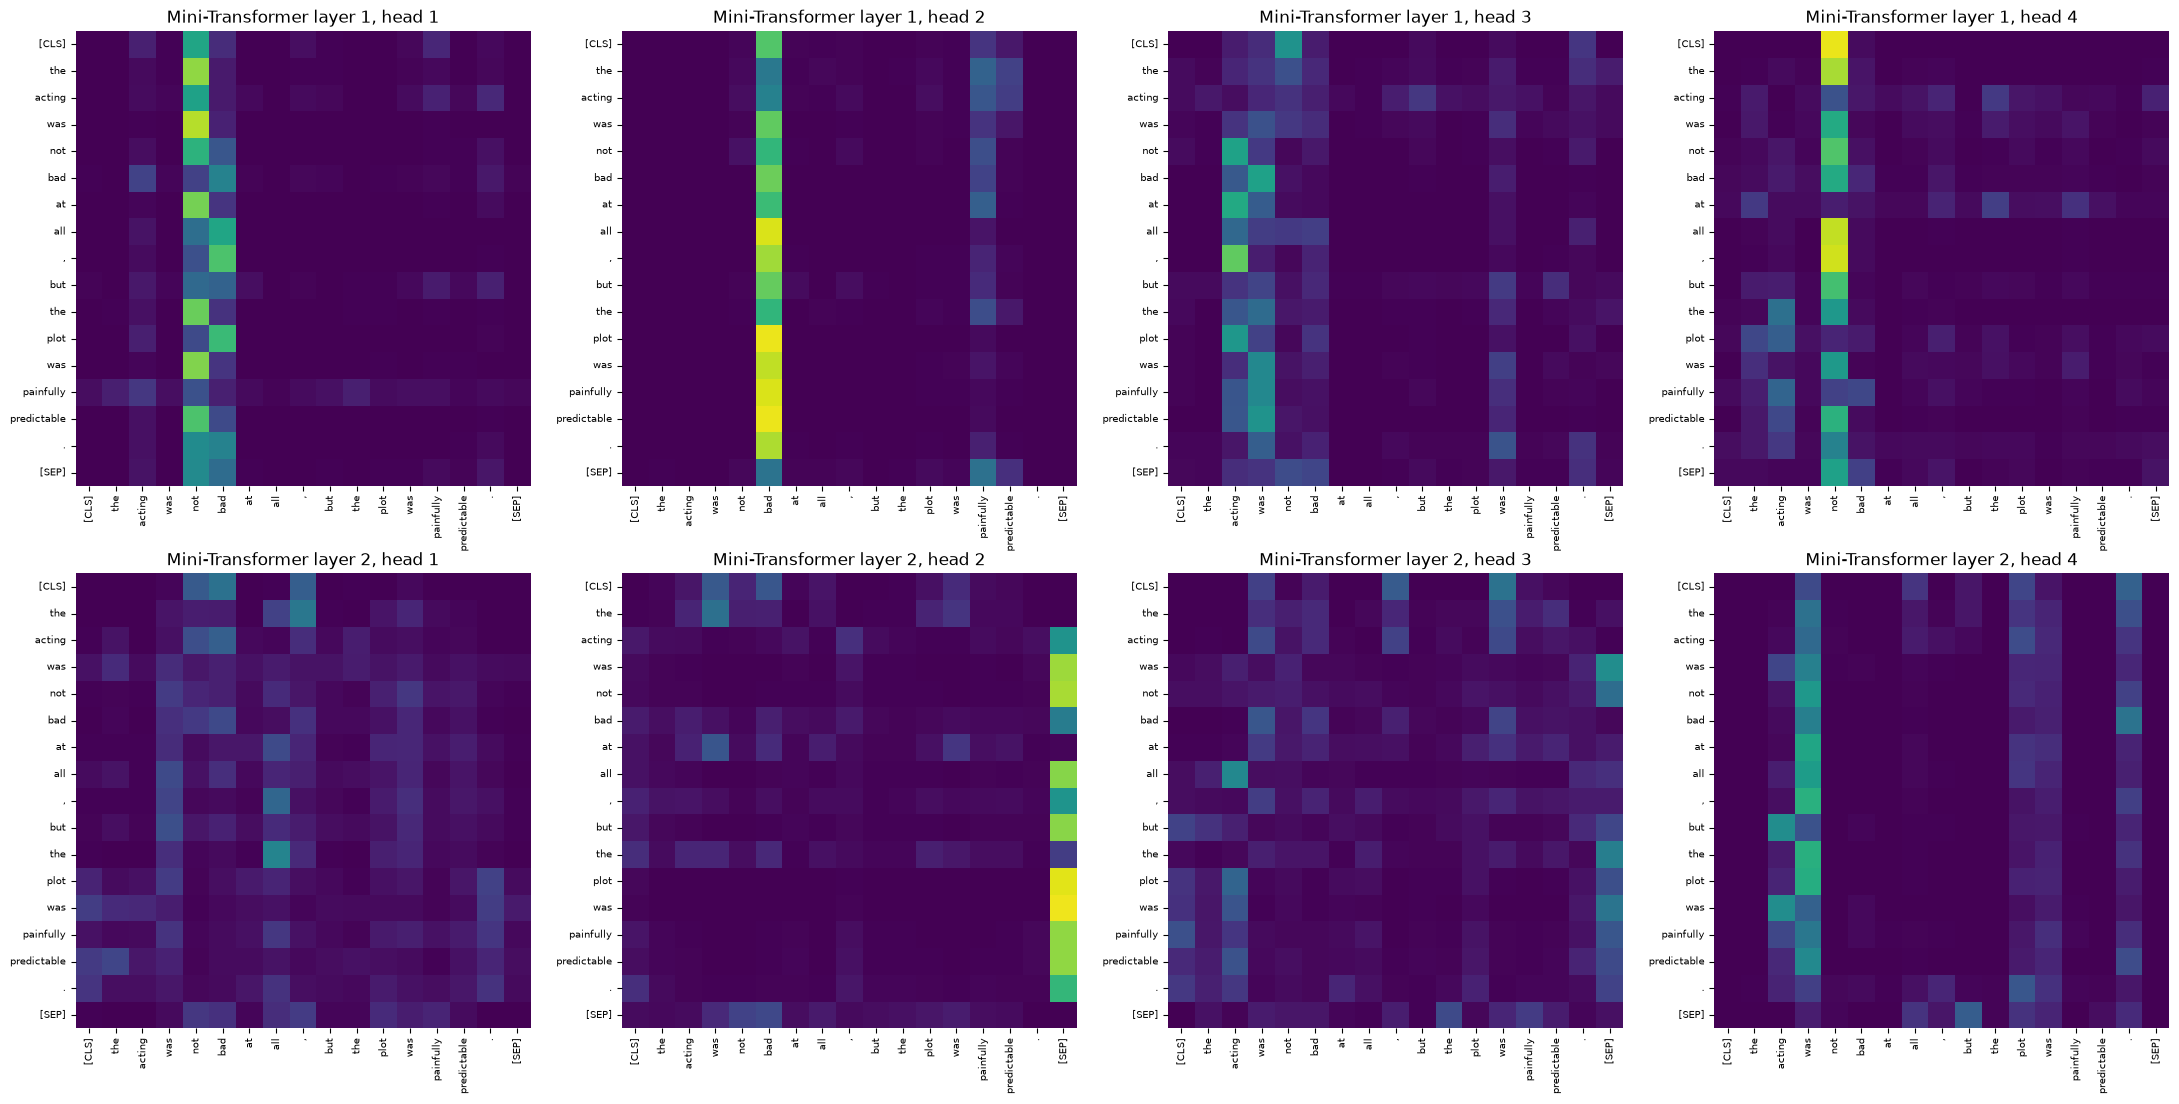

,Mini L1 (avg),Mini L2 (avg),Mini max over heads,BERT L1 (avg),BERT L12 (avg),BERT max over heads
prev,0.049,0.047,0.055,0.124,0.038,0.706
next,0.048,0.050,0.052,0.096,0.050,0.950
self,0.047,0.035,0.051,0.076,0.113,0.491
[CLS],0.011,0.016,0.023,0.125,0.052,0.882
[SEP],0.012,0.030,0.067,0.052,0.346,0.856
entropy,0.574,0.576,0.687,0.762,0.645,0.961


In [24]:
# attention of the from-scratch Mini-Transformer on the same sentence
mini_model.eval()
enc = tokenizer(sentence, return_tensors="pt").to(device)
with torch.no_grad():
    mini_logits = mini_model(enc["input_ids"], enc["attention_mask"])
mini_attn = [blk.mha.attn_weights[0].cpu() for blk in mini_model.blocks]          # 2 x (4, T, T)
print("mini-Transformer prediction:", id2label[int(mini_logits.argmax())],
      f"(p = {mini_logits.softmax(-1).max():.3f})")

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for l in range(2):
    for h in range(4):
        sns.heatmap(mini_attn[l][h].numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis", vmin=0, vmax=1,
                    ax=axes[l, h], square=True, cbar=False)
        axes[l, h].set_title(f"Mini-Transformer layer {l + 1}, head {h + 1}")
        axes[l, h].tick_params(axis="x", rotation=90, labelsize=7); axes[l, h].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

# same statistics as for BERT, averaged over the same 200 test sentences
def mini_get(m, enc):
    m(enc["input_ids"], enc["attention_mask"])
    return [blk.mha.attn_weights[0].cpu() for blk in m.blocks]
S_mini = head_stats(mini_model, probe, mini_get)                                  # (2, 4, 6)
cmp = pd.DataFrame({
    "Mini L1 (avg)": S_mini[0].mean(0), "Mini L2 (avg)": S_mini[1].mean(0),
    "Mini max over heads": S_mini.reshape(-1, 6).max(0),
    "BERT L1 (avg)": S[0].mean(0), "BERT L12 (avg)": S[11].mean(0),
    "BERT max over heads": S.reshape(-1, 6).max(0)}, index=STAT_NAMES)
cmp.round(3)

### 6.3 Answers

Evidence: the heatmaps above and the per-head statistics averaged over 200 test sentences.

**1. Next/previous-token heads and `[CLS]`/`[SEP]` heads - yes, several.**
* *Next token:* **layer 3, head 10** puts on average **95 %** of its attention on the next token, a nearly perfect shifted diagonal. **Layer 1, head 11** (top-right heatmap) shows the same pattern in the very first layer.
* *Previous token:* **layer 4, head 6** puts **71 %** on the previous token. The best previous-token head in layer 1 (head 3, top-left) is weaker: it shows a faint sub-diagonal but sends most of its weight to `[CLS]`.
* *`[CLS]`:* **layer 2, head 7** puts **88 %** of its attention on `[CLS]`. Layers 2-3 send on average 34-36 % of all attention there.
* *`[SEP]`:* **layer 5, head 4** puts **86 %** on `[SEP]`. In layers 5-9 about **half of all attention** goes to `[SEP]`. This is the well-known "no-op" pattern (Clark et al., 2019): when a head has nothing useful to do for a token, it parks its probability mass on a special token.

**2. Early vs. late layers.**
* *Early layers (1-4)* are **positional/local**: diagonal stripes (previous/next/self) and broad attention. Layer 1 has the highest entropy (0.76), so its heads mix the local context.
* *Middle layers (5-9)* are dominated by the `[SEP]` sink and have the *lowest* entropy (~0.40-0.51). Only a few heads do real work for each token.
* *Late layers (10-12)* use the `[SEP]` sink less (0.39 → 0.35) and their attention becomes broader again (entropy 0.61-0.65). Their patterns are **task-specific**: in our sentence, layers 11-12 send a large share of attention to the **comma that separates "not bad at all" from "but the plot was painfully predictable"** and to `[SEP]`, and layer 12, head 10 links *acting → plot*. Fine-tuning changes the top layers most, and they gather the clause-level information the classifier needs.

**3. Comparison with the from-scratch model.** The mini-Transformer's heads are **not structured in the same way**:
* It has **no positional heads**. Its best previous/next-token weight is 0.055, which is just the uniform 1/T level, compared with 0.95 for BERT. It also has no special-token sinks (attention to `[CLS]` ≤ 0.02).
* Instead, its heads form **vertical stripes**: every token attends to the same *sentiment keyword*. Layer-1 heads 1 and 4 focus on **"not"**, head 2 on **"bad"**, and a layer-2 head on `[SEP]`/"was". Its attention is therefore peaked (entropy ≈ 0.57), but on the *content* of a few words rather than on sentence structure. It behaves like a learned weighted bag-of-words.
* **Why:** the mini model has only 2 layers and was trained on 5,000 labelled phrases, and the only training signal is "positive/negative". Spotting a few polar words is enough to reduce that loss, so there is no pressure to learn syntax or word order. BERT's structured heads come from **pre-training on 3.3 B words** with Masked LM, which rewards learning local context, phrase structure, and which tokens to ignore.

## Bonus (+5): DistilBERT

`distilbert-base-uncased` is a 6-layer student of BERT-base, trained by knowledge distillation. It has no token-type embeddings and no pooler. It is fine-tuned here with exactly the same settings as full BERT (lr 2e-5, 3 epochs, batch 32). It uses the same uncased WordPiece vocabulary, but its tokenizer does not return `token_type_ids`, so the data is re-tokenised.

In [25]:
DISTIL = "distilbert-base-uncased"
distil_tok = AutoTokenizer.from_pretrained(DISTIL)

def prepare_distil(ds):
    return (ds.map(lambda b: distil_tok(b["sentence"], truncation=True, max_length=MAX_LEN), batched=True,
                   remove_columns=["sentence", "idx"]).rename_column("label", "labels"))

d_train, d_val, d_test = prepare_distil(train_ds), prepare_distil(val_ds), prepare_distil(test_ds)
set_seed(SEED)
distil_model = AutoModelForSequenceClassification.from_pretrained(DISTIL, num_labels=2, id2label=id2label, label2id=label2id,
                                              attn_implementation=ATTN_IMPL)
print(f"DistilBERT parameters: {count_params(distil_model):,} ({count_params(distil_model) / n_bert * 100:.0f}% of BERT-base)\n")

distil_trainer, distil_test, distil_time = run_trainer(
    distil_model, "distilbert-full", lr=2e-5, train=d_train, val=d_val, test=d_test,
    collator=DataCollatorWithPadding(distil_tok), tok=distil_tok)

# inference speed: time to classify the whole test set
def inference_time(trainer, ds):
    t0 = time.time(); trainer.predict(ds); return time.time() - t0
bert_inf, distil_inf = inference_time(bert_trainer, test_tok), inference_time(distil_trainer, d_test)
print(f"\ninference on 872 test sentences: BERT {bert_inf:.2f}s | DistilBERT {distil_inf:.2f}s "
      f"({bert_inf / distil_inf:.2f}x faster)")

results["DistilBERT (full fine-tune) [bonus]"] = {
    "Params": count_params(distil_model, False), "Trainable": count_params(distil_model), "Pre-trained": "Yes",
    "Test Acc": distil_test["test_accuracy"], "Test F1": distil_test["test_f1"], "Train time (s)": distil_time}


Map:   0%|          | 0/5000 [00:00<?, ? examples/s]


Map:  60%|██████    | 3000/5000 [00:00<00:00, 28179.89 examples/s]


Map: 100%|██████████| 5000/5000 [00:00<00:00, 31102.32 examples/s]


Map:   0%|          | 0/872 [00:00<?, ? examples/s]


Map: 100%|██████████| 872/872 [00:00<00:00, 45017.89 examples/s]


Map:   0%|          | 0/872 [00:00<?, ? examples/s]

... (6 outputs left out)

{'loss': 0.143, 'grad_norm': 0.401179701089859, 'learning_rate': 4.246284501061571e-08, 'epoch': 3.0}


{'eval_loss': 0.278739333152771, 'eval_accuracy': 0.8990825688073395, 'eval_f1': 0.9081419624217119, 'eval_runtime': 2.6227, 'eval_samples_per_second': 332.486, 'eval_steps_per_second': 5.338, 'epoch': 3.0}
{'train_runtime': 182.562, 'train_samples_per_second': 82.164, 'train_steps_per_second': 2.58, 'train_loss': 0.26155181852369047, 'epoch': 3.0}
 epoch  train_loss  eval_loss  eval_accuracy  eval_f1
   1.0      0.4233   0.266082       0.893349 0.901795
   2.0      0.2183   0.254028       0.901376 0.909474
   3.0      0.1430   0.278739       0.899083 0.908142


{'test_loss': 0.33950838446617126, 'test_accuracy': 0.8681192660550459, 'test_f1': 0.8732083792723263, 'test_runtime': 3.0654, 'test_samples_per_second': 284.466, 'test_steps_per_second': 4.567, 'epoch': 3.0}

distilbert-full: TEST accuracy = 0.8681 | F1 = 0.8732 | training time = 182.7s



inference on 872 test sentences: BERT 6.43s | DistilBERT 3.09s (2.08x faster)


**Bonus - speed/accuracy trade-off.** DistilBERT has **61 % of BERT's parameters** (67.0 M vs. 109.5 M; 6 layers instead of 12). Here it trained in **182.7 s vs. 329.6 s (1.8× faster)** and classified the test set **2.1× faster** (3.1 s vs. 6.4 s). In exchange it lost **2.8 accuracy points** (86.8 % vs. 89.6 %) and 2.6 F1 points. On validation the gap was smaller (90.1 % vs. 92.0 % at best). Overall, DistilBERT is a good choice when latency or memory matters, for example on CPU or mobile serving, and full BERT is better when the last few points of accuracy matter. Both are far ahead of the scratch model, so knowledge distillation keeps most of the benefit of pre-training.

## Part 7: Comparative Analysis & Reflection (5 points)

Fill in the table with your measured results.

| Model | Params | Pre-trained | Test Acc | Test F1 | Train time |
|---|---|---|---|---|---|
| Mini-Transformer (scratch) | 4.17 M (all trainable) | No | 0.7213 | 0.7466 | 17.7 s |
| BERT (frozen, head only) | 109.5 M (1,538 trainable) | Yes | 0.7030 | 0.7545 | 130.0 s |
| BERT (full fine-tune) | 109.5 M (all trainable) | Yes | **0.8956** | **0.8992** | 329.6 s |
| *DistilBERT (full fine-tune) - bonus* | *67.0 M (all trainable)* | *Yes* | *0.8681* | *0.8732* | *182.7 s* |

*Training times were measured on an Apple-Silicon GPU (MPS, fp32). On a Colab T4 with `fp16=True` the BERT runs are faster, but the relative order stays the same. Test set = the 872-sentence GLUE SST-2 validation split.*

**Answer briefly (3–5 lines each):**
1. Why does BERT outperform the same-architecture model trained from scratch, even though both use self-attention?
2. BERT is *encoder-only* and bidirectional, while the Lab 9 Marian model is *encoder-decoder*. Why is BERT unsuitable for generating translations directly?
3. What is the purpose of multiple heads rather than one big head? Give evidence from Part 6.
4. Compare the three paradigms from Labs 8, 9 and 10: *LSTM + attention*, *pre-trained seq2seq Transformer*, *pre-trained encoder (BERT)*. When would you use each?


                                     Params    Trainable Pre-trained Test Acc Test F1 Train time (s)
Mini-Transformer (scratch)             4.2M    4,172,034          No   0.7213  0.7466           17.7
BERT (full fine-tune)                109.5M  109,483,778         Yes   0.8956  0.8992          329.6
BERT (frozen, head only)             109.5M        1,538         Yes   0.7030  0.7545          130.0
DistilBERT (full fine-tune) [bonus]   67.0M   66,955,010         Yes   0.8681  0.8732          182.7


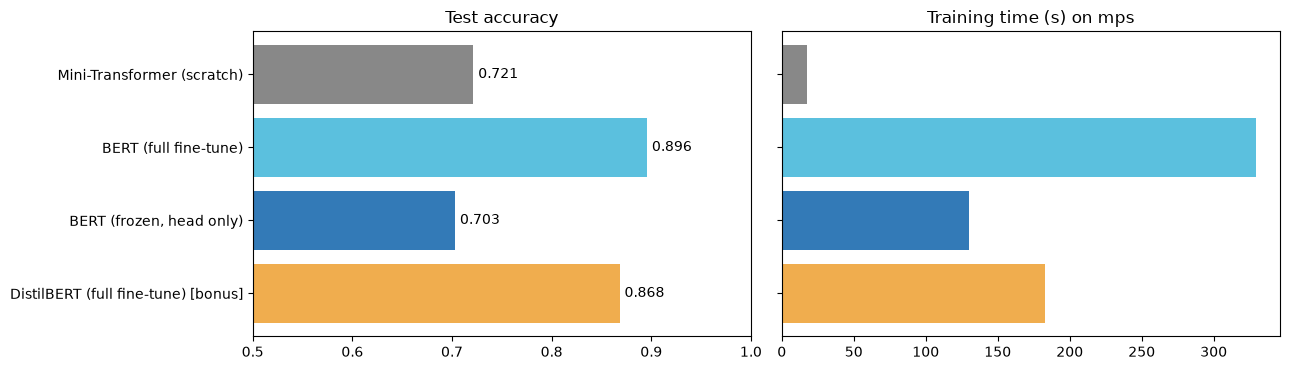

In [26]:
final = pd.DataFrame(results).T[["Params", "Trainable", "Pre-trained", "Test Acc", "Test F1", "Train time (s)"]]
display_df = final.copy()
display_df["Params"] = display_df["Params"].map(lambda x: f"{int(x) / 1e6:.1f}M")
display_df["Trainable"] = display_df["Trainable"].map(lambda x: f"{int(x):,}")
for c in ["Test Acc", "Test F1"]: display_df[c] = display_df[c].map(lambda x: f"{x:.4f}")
display_df["Train time (s)"] = display_df["Train time (s)"].map(lambda x: f"{x:.1f}")
print(display_df.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
names = list(final.index)
colors = ["#888888", "#5bc0de", "#337ab7", "#f0ad4e"][: len(names)]
axes[0].barh(names, final["Test Acc"].astype(float), color=colors)
axes[0].set_xlim(0.5, 1.0); axes[0].set_title("Test accuracy")
for i, v in enumerate(final["Test Acc"].astype(float)): axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")
axes[1].barh(names, final["Train time (s)"].astype(float), color=colors); axes[1].set_title(f"Training time (s) on {device.type}")
for ax in axes: ax.invert_yaxis()
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

### Part 7 - Answers

**1. Why does BERT beat the same kind of architecture trained from scratch?** Both models use self-attention, but **what they start from** is very different. BERT starts with contextual representations learned by Masked-LM pre-training on 3.3 B words, so it already "knows" word meanings, syntax, negation and how phrases combine. The scratch model has to learn everything, including the meaning of 30 k word embeddings (93.6 % of its parameters), from just 5,000 labelled phrases, and most words appear rarely or never. BERT is also deeper (12 layers / 12 heads / 768 dims vs. 2 / 4 / 128). The result is 89.6 % vs. 72.1 % accuracy. The difference shows on composition: the scratch model's attention just looks for keywords like "not"/"bad" (Part 6), while BERT correctly reads "not bad at all" as positive (0.976).

**2. Why is BERT unsuitable for translation on its own?** BERT is **encoder-only**. It maps an input sequence to one vector per *input* position and has no decoder that produces a new sequence of a different length. It also has no cross-attention to condition target tokens on a source sentence. Its attention is **bidirectional**: every token sees future tokens, and it was trained to fill in masked tokens at fixed positions, not to generate left-to-right with a causal mask. `bert-base-uncased` also only has an English vocabulary. Marian (Lab 9) is an encoder-decoder: the encoder reads the source, and an autoregressive decoder with causal self-attention and cross-attention generates the target token by token.

**3. Why several heads instead of one big head?** One softmax yields *one* weighted average per token, so a single head would have to blend all relationships into one distribution. It cannot, for example, put 95 % on the next token *and* 70 % on the previous token *and* attend to the clause boundary at the same time. With *h* heads in *d/h*-dimensional subspaces (same parameter count), each head can specialise. Part 6 shows this clearly: **L3-H10** is a next-token head (0.95), **L4-H6** a previous-token head (0.71), **L2-H7** a `[CLS]` head (0.88), **L5-H4** a `[SEP]`/no-op head (0.86), and late-layer heads attend to the clause-separating comma and link *acting ↔ plot*. Even in the tiny scratch model, different heads lock onto different cue words ("not" vs. "bad").

**4. When to use each paradigm (Labs 8, 9, 10).**
* **LSTM + attention (Lab 8):** small, trains from scratch, and needs no pre-trained checkpoint. Use it for low-resource or unusual domains or languages where no pre-trained model exists, for on-device or latency-constrained settings, or for teaching. It is sequential (slow to train on long sequences) and weaker on long-range context.
* **Pre-trained seq2seq Transformer, e.g. Marian (Lab 9):** use it whenever the **output is a new sequence**, such as translation, summarisation, paraphrasing or question generation. You get pre-trained encoder and decoder plus cross-attention, and fine-tuning adapts it to a domain.
* **Pre-trained encoder, e.g. BERT (Lab 10):** use it for **understanding tasks with a fixed-size output**: sentence/pair classification (sentiment, NLI), token labelling (NER, POS), extractive QA, and embeddings for retrieval. Bidirectional context makes it the strongest choice for these, and DistilBERT or a frozen encoder trades a little accuracy for speed. It is the wrong tool for free-text generation.

## What to Submit
* The completed notebook with all outputs visible.
* The comparison table from Part 7 and your written answers.
* Screenshots (or outputs) of the attention heatmaps from Part 6.

**Bonus (+5):** Fine-tune a smaller model (`distilbert-base-uncased`) and add it to the table, commenting on the speed/accuracy trade-off.